# mPD3_SN | Figure 3

Saved SHINE results. Training seed 123; K=11; clustering seed 123.

Five-fit summaries use seeds 0, 1, 2, 123 and 1234. See [setup and data requirements](README.md).

In [1]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import shine
from shine import SHINE, normalize_counts
from shine.study import Section
from shine.plotting import spatial_results, regional_results, molecular_maps, attention_plot, save_panel

CASE = "mPD3_SN"
# Extract the figure-data archive into data/, or set SHINE_DATA_ROOT.
search_roots = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("SHINE_DATA_ROOT"):
    ROOT = Path(os.environ["SHINE_DATA_ROOT"]).expanduser().resolve()
else:
    ROOT = next((candidate for parent in search_roots
                 for candidate in (parent / "data", parent)
                 if (candidate / "revision_experiments").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Extract the figure-data archive into data/, or set SHINE_DATA_ROOT. See data/README.md.")
manifest_candidates = [p / name for p in search_roots
                       for name in ("sections.json", "notebooks/sections.json")]
manifest_candidates.append(ROOT / "SHINE-github/notebooks/sections.json")
MANIFEST = next((p for p in manifest_candidates if p.is_file()), None)
if MANIFEST is None:
    raise FileNotFoundError("Cannot find notebooks/sections.json.")
OUT = ROOT / "outputs/notebook_results_20261124" / CASE
OUT.mkdir(parents=True, exist_ok=True)
section = Section(ROOT, MANIFEST, CASE)
print("shine-omics", shine.__version__, "|", CASE, "|", len(section.spots), "paired spots")

shine-omics 0.1.0.dev1 | mPD3_SN | 2915 paired spots


## 1. Settings

Fixed figure settings and paired cohort. Source files are verified by SHA-256.

In [2]:
settings = {"Figure": section.config["figure"], "K": section.config["K"],
            "epochs": 120, "training_seed": 123,
            "clustering_seed": section.config["display_clustering_seed"],
            "final_ReLU": True, **section.config["model_options"]}
display(pd.Series(settings, name="Final setting").to_frame())
display(section.spots.groupby(["region", "lesion"], dropna=False).size().rename("paired_spots").reset_index())

,Final setting
Figure,3
K,11
epochs,120
training_seed,123
clustering_seed,123
final_ReLU,True
loss,original
l2,True
spatial_floor,0.0
latent_dim,128


,region,lesion,paired_spots
0,CA1-CA2,intact,61
1,CA1-CA2,lesioned,130
2,CA3,intact,53
3,CA3,lesioned,22
4,DG,intact,55
5,DG,lesioned,46
6,HPF,intact,294
7,HPF,lesioned,230
8,Isocortex,intact,169
9,Isocortex,lesioned,181


## 2. Inputs

These paired matrices are already preprocessed. Do not repeat normalization or registration.

In [3]:
print(section.config["preprocessing"])
input_audit = pd.DataFrame([
    {"modality": name, "spots": x.shape[0], "features": x.shape[1],
     "finite": bool(np.isfinite(x).all()), "constant_rows": int((x.std(1) == 0).sum()),
     "minimum": float(x.min()), "maximum": float(x.max())}
    for name, x in [("RNA", section.rna), ("MSI", section.msi)]])
display(input_audit)
assert section.spots.spot.is_unique
assert np.allclose(section.xy, section.spots[["x", "y"]])
# For raw counts: normalize_counts(full_counts, feature_indices=frozen_columns)
# Do not renormalize section.rna or section.msi.

Frozen author SMA matched cohort. RNA and MSI total/TIC 10000/log1p; frozen 2000 RNA features. Do not refit registration, expand the cohort, or renormalize inputs.npz.


,modality,spots,features,finite,constant_rows,minimum,maximum
0,RNA,2915,2000,True,0,0.0,7.504290
1,MSI,2915,1538,True,0,0.0,8.150586


## 3. Graphs

H5 + H20; spatial kNN6; feature correlation-kNN20; local self+6 attention. Graphs use no annotation labels.

In [4]:
data, graphs = section.prepare()
display(pd.Series(graphs["audit"], name="Graph audit").to_frame())
print("Validated tensor shape:", data.shape)
print("Input + graph fingerprint:", data.fingerprint())

<reference-environment>/site-packages/threadpoolctl.py:1214: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,Graph audit
n_spots,2915
spatial_k,6
feature_k,20
hyperedge_sizes,"[5, 20]"
n_hyperedges,5830
pca_components,30
pca_seed,0
constant_feature_rows,"[0, 0]"
allow_constant_feature_rows,True
labels_used,False


Validated tensor shape: (2915, 2000, 1538)


Input + graph fingerprint: 0e5f5258b92e198c0a1247f6a6e2948b5a42d485945cac2bce874ff0cdb001d7


## 4. Model

Replay the saved figure model. Set `RUN_NEW_TRAINING=True` for a separate 120-epoch fit.

In [5]:
model, labels, replay_audit = section.replay(data)
display(pd.Series(replay_audit).to_frame("Replay check"))
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    new_model = SHINE(**section.config["model_options"])
    def progress(record):
        if record["epoch"] % 20 == 0:
            print("Epoch", record["epoch"], "loss", round(record["total"], 5))
    new_model.fit(data, epochs=120, seed=123, lr=1e-4, weight_decay=1e-3, progress=progress)
    new_labels = new_model.cluster(section.config["K"], seed=section.config["display_clustering_seed"])
    new_model.save(OUT / "new_training_seed123.pt")
    display(section.score(new_labels))
else:
    print("Displaying the saved figure model.")

,Replay check
embedding_max_abs_error,0.0
figure_labels_exact,True
n_spots,2915
origin,saved figure checkpoint; new package inference


Displaying the saved figure model.


## 5. ARI and NMI

Average five clustering seeds within each fit, then report mean and sample SD over five training seeds. Regional scores retain whole-section cluster IDs.

In [6]:
display_metrics = section.score(labels)
raw_metrics, per_fit, summary = section.five_fit_metrics()
print("Displayed fit: seed 123")
display(display_metrics.round(4))
print("Five fits: mean and sample SD")
display(summary.round(4))
display(per_fit.round(4))
for name, table in [("display_metrics", display_metrics), ("all_partitions", raw_metrics),
                    ("per_training_fit", per_fit), ("five_fit_summary", summary)]:
    table.to_csv(OUT / (name + ".csv"), index=False)

Displayed fit: seed 123


,endpoint,n_scored,ARI,NMI
0,Whole section,2737,0.3759,0.4689
1,SNr,150,0.1352,0.3059
2,VTA-SNc,233,0.0891,0.1538


Five fits: mean and sample SD


,endpoint,ARI_mean,ARI_std,NMI_mean,NMI_std,n_fits
0,SNr,0.1273,0.0914,0.2856,0.0945,5
1,VTA-SNc,0.0705,0.0265,0.1433,0.0485,5
2,Whole section,0.3413,0.0103,0.4651,0.0128,5


,endpoint,training_seed,ARI,NMI
0,SNr,0,-0.0301,0.1181
1,SNr,1,0.1862,0.3320
2,SNr,2,0.1810,0.3456
3,SNr,123,0.1246,0.3135
4,SNr,1234,0.1748,0.3189
5,VTA-SNc,0,0.0314,0.0653
6,VTA-SNc,1,0.0819,0.1686
7,VTA-SNc,2,0.0556,0.1275
8,VTA-SNc,123,0.0955,0.1842
9,VTA-SNc,1234,0.0879,0.1708


## 6. Spatial partition and UMAP

Colors are matched to annotations for display only. UMAP is not used for clustering or scoring.

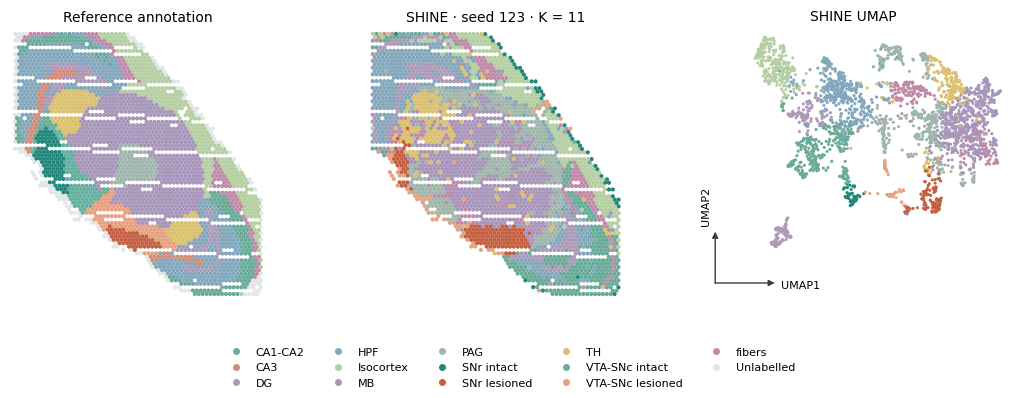

In [7]:
import umap
saved_embedding = np.load(section.path("embedding_123"))
umap_xy = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=123, n_jobs=1).fit_transform(saved_embedding)
fig = spatial_results(section, labels, umap_xy)
save_panel(fig, OUT / "seed123_spatial_UMAP")
plt.show()
spatial_source = section.spots.copy()
spatial_source["SHINE_cluster"] = labels
spatial_source[["UMAP1", "UMAP2"]] = umap_xy
spatial_source.to_csv(OUT / "seed123_spatial_source.csv", index=False)

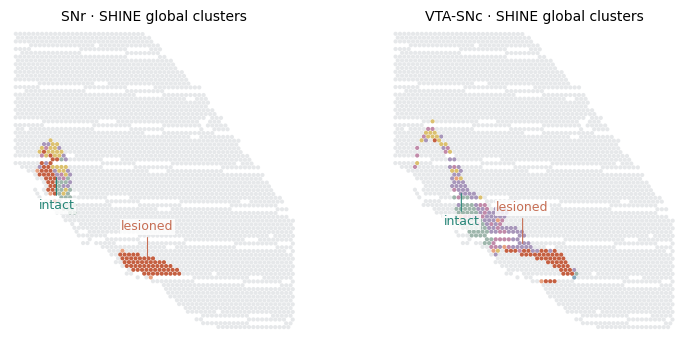

In [8]:
fig = regional_results(section, labels)
save_panel(fig, OUT / "seed123_regions")
plt.show()

## 7. Attention

Spatial-branch weights within RNA and MSI. These are mixing weights, not causal importance.

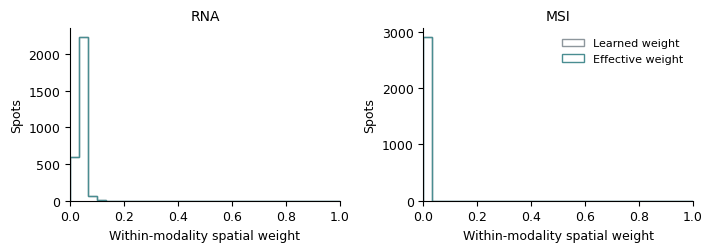

,RNA_spatial_raw,RNA_spatial_effective,MSI_spatial_raw,MSI_spatial_effective
count,2915.000,2915.000,2915.000,2915.000
mean,0.040,0.040,0.016,0.016
std,0.010,0.010,0.002,0.002
min,0.022,0.022,0.012,0.012
25%,0.034,0.034,0.015,0.015
50%,0.038,0.038,0.016,0.016
75%,0.044,0.044,0.017,0.017
max,0.134,0.134,0.032,0.032


In [9]:
fig = attention_plot(model)
save_panel(fig, OUT / "attention_weights")
plt.show()
attention_source = pd.DataFrame({"spot": section.spots.spot,
    "RNA_spatial_raw": model.attention_["rna_raw"][:, 0],
    "RNA_spatial_effective": model.attention_["rna"][:, 0],
    "MSI_spatial_raw": model.attention_["msi_raw"][:, 0],
    "MSI_spatial_effective": model.attention_["msi"][:, 0]})
attention_source.to_csv(OUT / "attention_source.csv", index=False)
display(attention_source.drop(columns="spot").describe().round(3))

## 8. Measured genes and MSI peaks

Figure 3 markers, compared within SNr and VTA–SNc by anatomical side. MSI labels are measured m/z values.

RNA: ['Th', 'Slc6a3', 'Ddc', 'Slc18a2', 'Aldh1a1', 'Penk', 'Tac1', 'Drd1']
MSI m/z: ['674.2805', '435.20692']


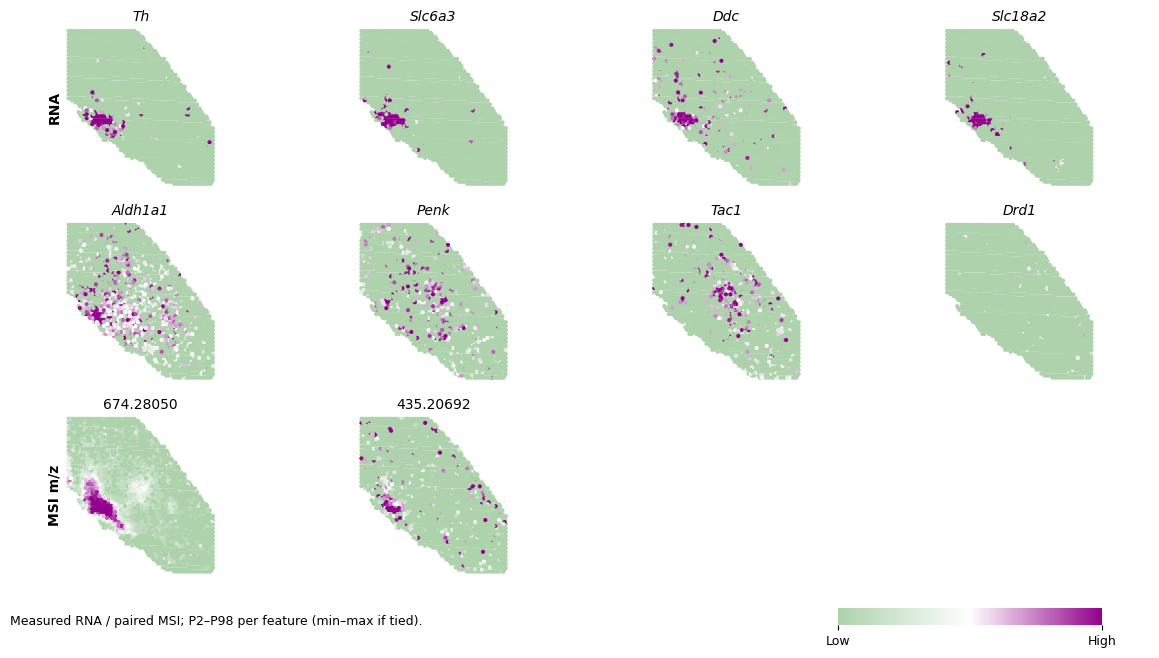

,contrast,feature,n_reference,n_target,mean_reference,mean_target,difference_SD
0,SNr: lesioned minus intact,Th,94,56,0.664,0.000,-0.659
1,SNr: lesioned minus intact,Slc6a3,94,56,0.770,0.035,-0.686
2,SNr: lesioned minus intact,Ddc,94,56,0.653,0.063,-0.639
3,SNr: lesioned minus intact,Slc18a2,94,56,0.436,0.018,-0.535
4,SNr: lesioned minus intact,Aldh1a1,94,56,1.079,0.654,-0.383
5,SNr: lesioned minus intact,Penk,94,56,0.270,0.168,-0.154
6,SNr: lesioned minus intact,Tac1,94,56,0.104,0.000,-0.266
7,SNr: lesioned minus intact,Drd1,94,56,0.016,0.011,-0.041
8,SNr: lesioned minus intact,674.2805,94,56,2.000,0.186,-1.630
9,SNr: lesioned minus intact,435.20692,94,56,0.174,0.063,-0.375


In [10]:
molecules = section.molecular_values()
print("RNA:", section.config["display_genes"])
print("MSI m/z:", section.config["display_peaks"])
fig = molecular_maps(section, molecules)
save_panel(fig, OUT / "measured_molecules")
plt.show()
measured_source = pd.concat([section.spots[["spot", "x", "y", "region", "lesion"]], molecules], axis=1)
measured_source.to_csv(OUT / "measured_molecule_source.csv", index=False)
effects = section.molecular_comparison(molecules, labels)
display(effects.round(3))
effects.to_csv(OUT / "measured_molecule_effects.csv", index=False)

## 9. RNA–MSI associations

Correlations are calculated separately by region and side. Constant or sparsely detected signals are flagged.

In [11]:
section.verify("molecular_associations")
associations = pd.read_csv(section.path("molecular_associations"))
associations = associations[associations.animal.eq(section.config["animal"])]
display(associations)
associations.to_csv(OUT / "gene_MSI_associations.csv", index=False)

,case,animal,region,side,gene,peak,n_spots,gene_positive,peak_positive,both_positive,rho,status,n_blocks,n_estimable_deletions,deletion_min,deletion_max
0,B1,mPD3,CP,intact,Th,674.28050,299,9,299,9,0.041433,shown,25,25,0.019931,0.081900
1,B1,mPD3,CP,intact,Th,435.20692,299,9,299,9,0.092111,shown,25,25,0.076165,0.121104
2,B1,mPD3,CP,intact,Th,674.28592,299,9,299,9,-0.048450,shown,25,25,-0.069940,-0.014108
3,B1,mPD3,CP,intact,Slc6a3,674.28050,299,0,299,0,NaN,constant,25,0,NaN,NaN
4,B1,mPD3,CP,intact,Slc6a3,435.20692,299,0,299,0,NaN,constant,25,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283,mPD3_SN,mPD3,VTA-SNc,lesioned,Ppp1r1b,435.20692,115,8,15,1,0.005503,shown,16,16,-0.096076,0.043208
284,mPD3_SN,mPD3,VTA-SNc,lesioned,Ppp1r1b,674.28592,115,8,63,7,0.220776,shown,16,16,0.164871,0.288238
285,mPD3_SN,mPD3,VTA-SNc,lesioned,Rasd2,674.28050,115,16,80,11,0.023719,shown,16,16,-0.061706,0.123937
286,mPD3_SN,mPD3,VTA-SNc,lesioned,Rasd2,435.20692,115,16,15,1,-0.067787,shown,16,16,-0.131201,-0.031098


## 10. Validation and exports

Saved-model replay and fresh training are reported separately. Fresh fits do not replace the figure model.

In [7]:
validation_dir = ROOT / "outputs/shine_omics_notebooks_validation_20261124" / CASE
for filename in ["replay_validation.json", "fresh_training_validation.json"]:
    path = validation_dir / filename
    if path.exists():
        display(pd.Series(json.loads(path.read_text()), name=filename).to_frame())
    else:
        print(filename, "Not available; training validation is incomplete.")
provenance = {"case": CASE, "package_version": shine.__version__, "settings": settings,
              "replay": replay_audit, "sources": section.config["sources"],
              "statistical_unit": "training seed; sample SD over five fits",
              "spatial_train_seed": 123, "new_training_replaces_figure": False}
(OUT / "notebook_provenance.json").write_text(json.dumps(provenance, indent=2))
print("Output directory:", OUT)

,replay_validation.json
embedding_max_abs_error,0.0
figure_labels_exact,True
n_spots,2915
origin,saved figure checkpoint; new package inference
graph_audit,"{'n_spots': 2915, 'spatial_k': 6, 'feature_k':..."
data_fingerprint,0e5f5258b92e198c0a1247f6a6e2948b5a42d485945cac...
seconds,50.407452


,fresh_training_validation.json
validation_key,ae6956ea7f5600ac461c5b3b2265b253b74a65031d2777...
case,mPD3_SN
epochs,120
training_seed,123
seconds,824.203645
finite_embedding,True
fresh_vs_historical_max_abs_error,0.000002
partition_ARI_vs_historical,1.0
main_figure_overwritten,False


Output directory: $SHINE_DATA_ROOT/outputs/notebook_results_20261124/mPD3_SN
